In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import time

def min_max_scaler(min, max, x):
    return (x - min) / (max - min)

np.random.seed(0)

In [2]:
n_gaussian_dim = 2
n_signal_events_p = 50000
n_signal_events_n = int(0.4 * n_signal_events_p)
n_signal_events = n_signal_events_p + n_signal_events_n
n_signal_hypothesis = 10
n_bg_events = 4 * n_signal_events
theta_bg = 5.0
theta_signal = np.linspace(2,8,10)
min_theta = min(theta_signal)
max_theta = max(theta_signal)
if len(theta_signal) != n_signal_hypothesis:
    raise ValueError("Length of theta_signal must be equal to n_signal_hypothesis")

# Create the data for SIGNAL
signal_X = np.empty(shape = (0, n_gaussian_dim + 1 + 1)) # +1 for theta, +1 for weight
signal_category = np.empty(shape=(0,1),dtype = np.float32)
category = 1
for itheta in theta_signal:
    # Parameter
    new_signal_theta = np.full(shape = (n_signal_events, 1), fill_value = min_max_scaler(min_theta, max_theta, itheta))
    # Data
    new_signal_X_p = np.random.normal(loc = itheta, scale = 2.0, size = (n_signal_events_p, n_gaussian_dim))
    new_signal_X_n = np.random.normal(loc = itheta, scale = 1.0, size = (n_signal_events_n, n_gaussian_dim))
    new_signal_X = np.concatenate((new_signal_X_p, new_signal_X_n), axis = 0)
    # Weights
    weight_signal_p = np.full(shape = (n_signal_events_p, 1), fill_value = 1)
    weight_signal_n = np.full(shape = (n_signal_events_n, 1), fill_value = -1)
    weight_signal = np.concatenate((weight_signal_p, weight_signal_n), axis = 0)
    # Category 
    new_signal_category = np.full(shape = (n_signal_events, 1), fill_value = category)

    # Add the data
    new_signal_data = np.concatenate((new_signal_X, new_signal_theta, weight_signal), axis = 1)
    signal_X = np.concatenate((signal_X, new_signal_data), axis = 0).astype(np.float32)
    signal_category =  np.concatenate((signal_category, new_signal_category), axis = 0).astype(np.float32)

    # For next category
    category += 1

bg_X = np.random.normal(loc = 5, scale = 2.0, size = (n_bg_events, n_gaussian_dim))
bg_theta = np.random.choice(signal_X[:,-2], size=(n_bg_events, 1)).astype(np.float32)
weight_bg = np.full_like(bg_theta, fill_value=0.25)
bg_X = np.concatenate((bg_X, bg_theta, weight_bg), axis = 1)
print("Signal data shape:", signal_X.shape)
print("Background data shape:", bg_X.shape)

# Create the labels
signal_y = np.ones(shape = (signal_X.shape[0],1), dtype = np.float32)
signal_y = np.concatenate((signal_y,signal_category),axis=1)
bg_y = np.zeros(shape = (bg_X.shape[0],1), dtype = np.float32)
bg_category = np.full(shape=(n_bg_events,1),fill_value=-1,dtype = np.float32)
bg_y = np.concatenate((bg_y,bg_category), axis=1)

# Combine datasets
X = np.concatenate((signal_X, bg_X), axis = 0)
y = np.concatenate((signal_y, bg_y), axis = 0)

Signal data shape: (700000, 4)
Background data shape: (280000, 4)


In [3]:
# Force CPU for MAC
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
if device == "mps":
    device = "cpu"
print(f"Using {device} device")

Using cpu device


In [4]:
# Split in train, val, test
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
train_indices, test_indices = next(sss.split(X, y))

X_train, y_train = X[train_indices], y[train_indices]
X_temp, y_temp = X[test_indices], y[test_indices]
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=True)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
scaler = ColumnTransformer(
    [('Std Scaler',StandardScaler(), list(range(n_gaussian_dim))),
    ],
    remainder='passthrough'
)

X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

# As tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32, device=device)
X_val_tensor   = torch.tensor(X_val, dtype=torch.float32, device=device)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32, device=device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32, device=device)
y_val_tensor   = torch.tensor(y_val, dtype=torch.float32, device=device)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32, device=device)

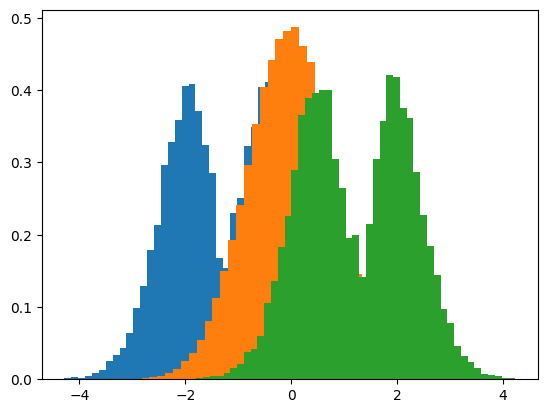

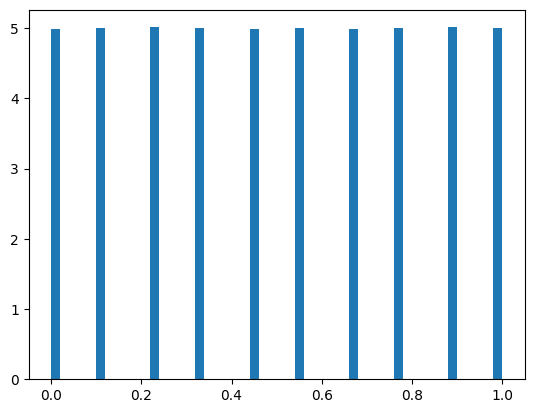

In [5]:
plt.hist(X_train[y_train[:,1]==1][:,1],bins=50, density= True, weights=X_train[y_train[:,1]==1][:,-1])
plt.hist(X_train[y_train[:,1]==-1][:,1],bins=50, density= True, weights=X_train[y_train[:,1]==-1][:,-1])
plt.hist(X_train[y_train[:,1]==10][:,1],bins=50, density= True, weights=X_train[y_train[:,1]==10][:,-1])
plt.show()

plt.hist(X_train[:,-2],bins=50, density= True)
plt.show()

In [12]:
from torch.utils.data import TensorDataset, DataLoader

def create_dataloaders(X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor, X_test_tensor, y_test_tensor, batch_size=1024, signal="positive", background="positive", weight_column_index=-1, label_column_index=0):
    # First check the signal and background types
    if signal not in ["positive", "negative"]:
        raise ValueError("Signal must be 'positive' or 'negative'")
    if background not in ["positive", "negative"]:
        raise ValueError("Background must be 'positive' or 'negative'")

    # Train dataset masks
    signal_mask = y_train_tensor[:, label_column_index] == 1
    background_mask = y_train_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask = X_train_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask = X_train_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask = X_train_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask = X_train_tensor[:, weight_column_index] < 0
    
    train_mask = (signal_mask & signal_weight_mask) | (background_mask & background_weight_mask)
    X_train = X_train_tensor[train_mask]
    y_train = y_train_tensor[train_mask]

    # Validation dataset masks
    signal_mask_val = y_val_tensor[:, label_column_index] == 1
    background_mask_val = y_val_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask_val = X_val_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask_val = X_val_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask_val = X_val_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask_val = X_val_tensor[:, weight_column_index] < 0

    val_mask = (signal_mask_val & signal_weight_mask_val) | (background_mask_val & background_weight_mask_val)
    X_val = X_val_tensor[val_mask]
    y_val = y_val_tensor[val_mask]

    # Test dataset masks
    signal_mask_test = y_test_tensor[:, label_column_index] == 1
    background_mask_test = y_test_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask_test = X_test_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask_test = X_test_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask_test = X_test_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask_test = X_test_tensor[:, weight_column_index] < 0

    test_mask = (signal_mask_test & signal_weight_mask_test) | (background_mask_test & background_weight_mask_test)
    X_test = X_test_tensor[test_mask]
    y_test = y_test_tensor[test_mask]


    # Form the datasets
    train_dataset = TensorDataset(X_train,
                                  y_train)
    val_dataset   = TensorDataset(X_val,
                                  y_val)
    test_dataset  = TensorDataset(X_test,
                                    y_test)

    # Create DataLoader objects for training, validation, and testing in batches
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=6, persistent_workers=True, drop_last=True)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=6, persistent_workers=True, drop_last=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=6)

    return train_loader, val_loader, test_loader

In [13]:
# Define the Classifier
class Classifier(nn.Module):
    def __init__(self, x_dim, theta_dim = 0, hidden_dim = 4):
        super(Classifier, self).__init__()
        self.theta_dim = theta_dim
        if self.theta_dim == 0:
            print("NN: Using non-parametric model.")
        else:
            print("NN: Using parametric model with theta dimension =", theta_dim)
        self.net = nn.Sequential(
            nn.Linear(x_dim + theta_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2*hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(2*hidden_dim, 2*hidden_dim),
            nn.ReLU(),
            nn.Linear(2*hidden_dim, 1),
        )

    def forward(self, X):
        logits = self.net(X)
        return logits

In [14]:
def train(model, criterion, optimizer, train_loader, val_loader, n_epochs=50, device='cpu'):
    start_time = time.time()
    train_losses = []
    val_losses = []
    num_epochs = n_epochs

    model.to(device)

    for epoch in range(num_epochs):
        epoch_start_time = time.time()
        model.train()
        # run over batches of data
        running_loss = 0.0
        for inputs, targets in train_loader:
            optimizer.zero_grad()
            inputs_device = inputs.to(device)
            targets_device = targets[:,0].to(device)
            outputs = model(inputs_device[:,:-1])
            outputs = torch.sigmoid(outputs)
            weights = abs(inputs_device[:,-1])
            loss = weights*criterion(outputs.squeeze(), targets_device)
            loss = torch.sum(loss)/len(loss)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        # compute avergae loss over all batches
        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        # Validation step
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs_device = inputs.to(device)
                targets_device = targets[:,0].to(device)
                outputs = model(inputs_device[:,:-1])
                outputs = torch.sigmoid(outputs)
                weights = abs(inputs_device[:,-1])
                loss = weights*criterion(outputs.squeeze(), targets_device)
                loss = torch.sum(loss)/len(loss)
                val_loss += loss.item()

        val_loss /= len(val_loader)
        val_losses.append(val_loss)

        current_time = time.time()
        print(f"Total Time: {round(current_time - start_time,1)}s, Epoch Time: {round(current_time - epoch_start_time,2)}s")
        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    # Plot loss function for training and validation sets
    plt.plot(train_losses, label='Train Loss', color='red')
    plt.plot(val_losses, label='Validation Loss', color='green')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Train Loss', 'Validation Loss'])
    plt.show()

In [15]:
# Define the different models and data loaders
import torch.optim as optim

# Model ++ (pp)
model_pp = Classifier(x_dim = n_gaussian_dim, theta_dim = 1, hidden_dim = 8)
criterion = nn.BCELoss(reduction='none')
optimizer_pp = optim.AdamW(model_pp.parameters(), lr=0.0002, weight_decay=0.001)

train_loader_pp, val_loader_pp, test_loader_pp = create_dataloaders(X_train_tensor, y_train_tensor,
                                                                X_val_tensor, y_val_tensor,
                                                                X_test_tensor, y_test_tensor,
                                                                batch_size=1024,
                                                                signal="positive",
                                                                background="positive")

NN: Using parametric model with theta dimension = 1


Total Time: 3.7s, Epoch Time: 3.74s
Epoch 1/200, Train Loss: 0.3401, Val Loss: 0.2608
Total Time: 4.5s, Epoch Time: 0.75s
Epoch 2/200, Train Loss: 0.2574, Val Loss: 0.2536
Total Time: 5.0s, Epoch Time: 0.56s
Epoch 3/200, Train Loss: 0.2527, Val Loss: 0.2508
Total Time: 5.7s, Epoch Time: 0.67s
Epoch 4/200, Train Loss: 0.2505, Val Loss: 0.2490
Total Time: 6.4s, Epoch Time: 0.67s
Epoch 5/200, Train Loss: 0.2488, Val Loss: 0.2474
Total Time: 7.2s, Epoch Time: 0.77s
Epoch 6/200, Train Loss: 0.2473, Val Loss: 0.2459
Total Time: 8.1s, Epoch Time: 0.94s
Epoch 7/200, Train Loss: 0.2458, Val Loss: 0.2445
Total Time: 8.8s, Epoch Time: 0.68s
Epoch 8/200, Train Loss: 0.2442, Val Loss: 0.2415
Total Time: 9.6s, Epoch Time: 0.79s
Epoch 9/200, Train Loss: 0.2392, Val Loss: 0.2358
Total Time: 10.4s, Epoch Time: 0.79s
Epoch 10/200, Train Loss: 0.2329, Val Loss: 0.2285
Total Time: 11.1s, Epoch Time: 0.72s
Epoch 11/200, Train Loss: 0.2250, Val Loss: 0.2203
Total Time: 11.7s, Epoch Time: 0.58s
Epoch 12/200,

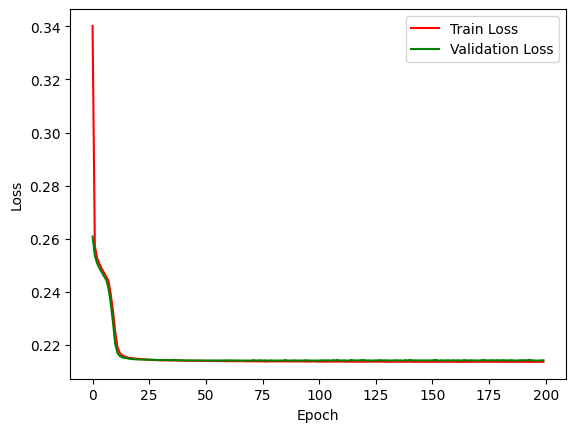

In [16]:
# Train pp model
train(model_pp, criterion, optimizer_pp, train_loader_pp, val_loader_pp, n_epochs=200, device=device)

In [17]:
# Model ++ (pn)
model_pn = Classifier(x_dim = n_gaussian_dim, theta_dim = 1, hidden_dim = 8)
criterion = nn.BCELoss(reduction='none')
optimizer_pn = optim.AdamW(model_pn.parameters(), lr=0.0002, weight_decay=0.001)

train_loader_pn, val_loader_pn, test_loader_pn = create_dataloaders(X_train_tensor, y_train_tensor,
                                                                X_val_tensor, y_val_tensor,
                                                                X_test_tensor, y_test_tensor,
                                                                batch_size=1024,
                                                                signal="negative",
                                                                background="positive")

NN: Using parametric model with theta dimension = 1


Total Time: 3.4s, Epoch Time: 3.4s
Epoch 1/200, Train Loss: 0.3350, Val Loss: 0.3158
Total Time: 3.9s, Epoch Time: 0.47s
Epoch 2/200, Train Loss: 0.3044, Val Loss: 0.2896
Total Time: 4.5s, Epoch Time: 0.58s
Epoch 3/200, Train Loss: 0.2773, Val Loss: 0.2639
Total Time: 5.1s, Epoch Time: 0.61s
Epoch 4/200, Train Loss: 0.2508, Val Loss: 0.2340
Total Time: 5.5s, Epoch Time: 0.4s
Epoch 5/200, Train Loss: 0.2241, Val Loss: 0.2085
Total Time: 5.9s, Epoch Time: 0.47s
Epoch 6/200, Train Loss: 0.2029, Val Loss: 0.1886
Total Time: 6.4s, Epoch Time: 0.49s
Epoch 7/200, Train Loss: 0.1874, Val Loss: 0.1755
Total Time: 6.8s, Epoch Time: 0.4s
Epoch 8/200, Train Loss: 0.1782, Val Loss: 0.1691
Total Time: 7.2s, Epoch Time: 0.39s
Epoch 9/200, Train Loss: 0.1737, Val Loss: 0.1667
Total Time: 7.8s, Epoch Time: 0.56s
Epoch 10/200, Train Loss: 0.1717, Val Loss: 0.1658
Total Time: 8.2s, Epoch Time: 0.41s
Epoch 11/200, Train Loss: 0.1702, Val Loss: 0.1652
Total Time: 8.6s, Epoch Time: 0.41s
Epoch 12/200, Train

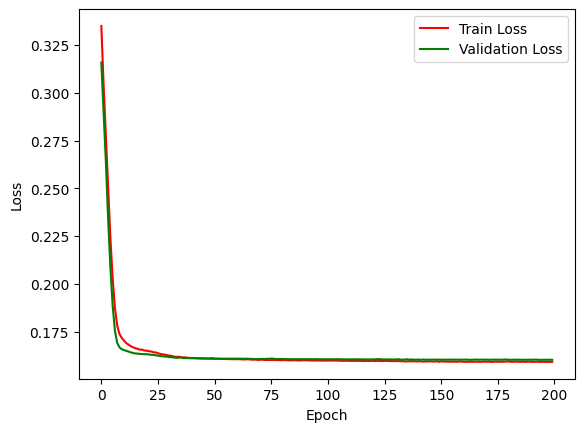

In [18]:
train(model_pn, criterion, optimizer_pn, train_loader_pn, val_loader_pn, n_epochs=200, device=device)

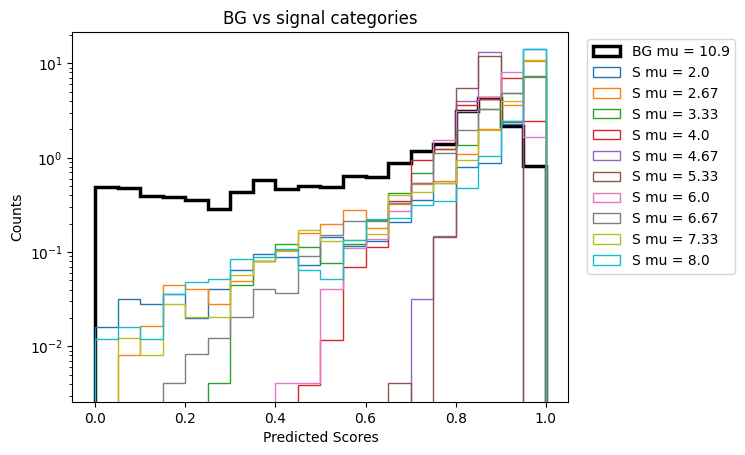

In [19]:
model_pp.to('cpu')
model_pp.eval()

# Use the test dataloader to get predictions
X_test_cpu = test_loader_pp.dataset.tensors[0].to('cpu')
y_test_cpu = test_loader_pp.dataset.tensors[1].to('cpu')

y_pred = torch.sigmoid(model_pp(X_test_cpu[:,:-1]).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test_cpu[:,0]
category_label = y_test_cpu[:,1]
true_bkg = y_pred[sb_label==0].numpy()

i_category = 1
plt.hist(true_bkg, bins=20,range=(0,1), histtype='step', label='Background', density=True, color='black', linewidth=2.5)
plt.xlabel("Predicted Scores")
plt.ylabel("Counts")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for i in range(1,11):
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==i_category].numpy()
    plt.hist(true_signal, bins=20, range=(0,1), histtype='step', label='Signal', density=True)
    signal_legends.append(f"S mu = %s" % str(round(theta_signal[i-1],2)))
    i_category += 1

plt.legend(["BG mu = 10.9"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

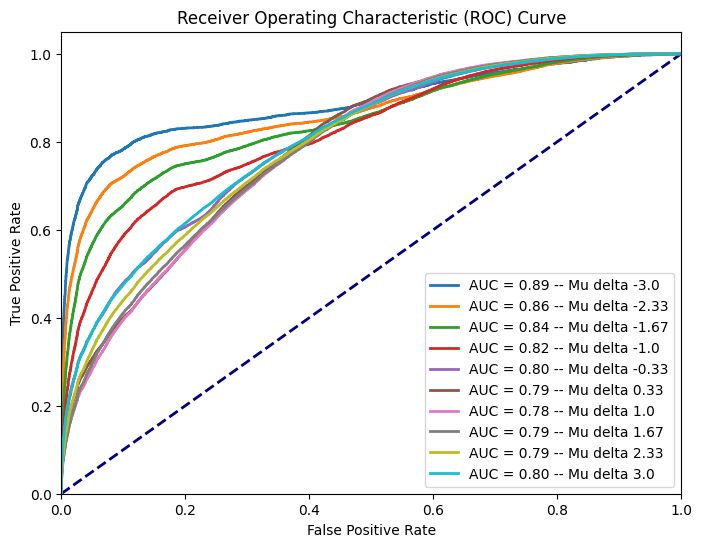

In [20]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in range(1,11):
    y_pred_cat = y_pred[category_label<=icat].numpy()
    y_test_cat = y_test_cpu[category_label<=icat]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- Mu delta {round(- theta_bg + theta_signal[icat-1],2)}')
    
plt.legend(loc='lower right')
plt.show()

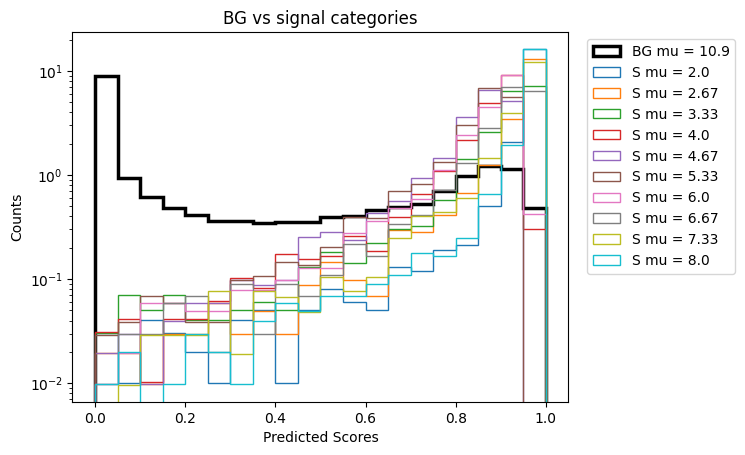

In [21]:
model_pn.to('cpu')
model_pn.eval()

# Use the test dataloader to get predictions
X_test_cpu = test_loader_pn.dataset.tensors[0].to('cpu')
y_test_cpu = test_loader_pn.dataset.tensors[1].to('cpu')

y_pred = torch.sigmoid(model_pn(X_test_cpu[:,:-1]).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test_cpu[:,0]
category_label = y_test_cpu[:,1]
true_bkg = y_pred[sb_label==0].numpy()

i_category = 1
plt.hist(true_bkg, bins=20,range=(0,1), histtype='step', label='Background', density=True, color='black', linewidth=2.5)
plt.xlabel("Predicted Scores")
plt.ylabel("Counts")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for i in range(1,11):
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==i_category].numpy()
    plt.hist(true_signal, bins=20, range=(0,1), histtype='step', label='Signal', density=True)
    signal_legends.append(f"S mu = %s" % str(round(theta_signal[i-1],2)))
    i_category += 1

plt.legend(["BG mu = 10.9"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

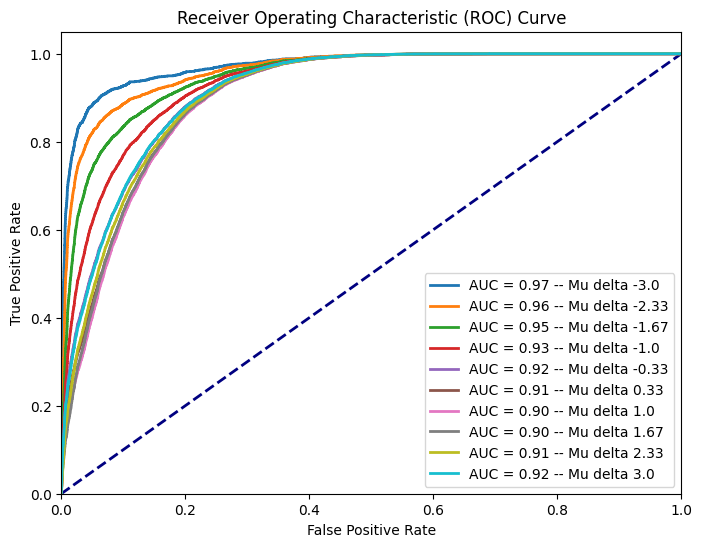

In [22]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in range(1,11):
    y_pred_cat = y_pred[category_label<=icat].numpy()
    y_test_cat = y_test_cpu[category_label<=icat]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- Mu delta {round(- theta_bg + theta_signal[icat-1],2)}')
    
plt.legend(loc='lower right')
plt.show()

In [23]:
# Calculate the mixture coefficcients

# C(y) = Sum(wi for wi >0) / Sum(wi) with wi belonging to the "y" category

# First C0 -> This is one because the BG weights are all positive
bg_mask = y_train[:,0]==0
signal_mask = y_train[:,0]==1
C_zero = (X_train[bg_mask & (X_train[:,-1]>=0)][:,-1]).sum()/ X_train[bg_mask][:,-1].sum() 
print("C0 =", C_zero)

# Now C1
C_one = (X_train[signal_mask & (X_train[:,-1]>=0)][:,-1]).sum()/ abs(X_train[signal_mask][:,-1]).sum() 
print("C1 =", C_one)

C0 = 1.0
C1 = 0.7146392857142857


(array([1.83207353e-04, 9.16036763e-05, 8.24433087e-04, 9.16036763e-04,
        1.92367720e-03, 4.48858014e-03, 1.22748926e-02, 2.31757301e-02,
        3.92979772e-02, 6.84279462e-02, 9.83823484e-02, 1.34932215e-01,
        1.62138507e-01, 1.59023982e-01, 1.32916934e-01, 1.00306026e-01,
        1.08916771e-01, 1.42901735e-01, 1.66443880e-01, 1.51787292e-01,
        1.20825249e-01, 8.33593455e-02, 5.40461690e-02, 3.17864757e-02,
        1.67634728e-02, 8.51914190e-03, 4.67178749e-03, 1.83207353e-03,
        6.41225734e-04, 2.74811029e-04]),
 array([-8.61982587, -8.07399625, -7.52816663, -6.98233701, -6.43650739,
        -5.89067777, -5.34484814, -4.79901852, -4.2531889 , -3.70735928,
        -3.16152966, -2.61570004, -2.06987041, -1.52404079, -0.97821117,
        -0.43238155,  0.11344807,  0.65927769,  1.20510732,  1.75093694,
         2.29676656,  2.84259618,  3.3884258 ,  3.93425542,  4.48008505,
         5.02591467,  5.57174429,  6.11757391,  6.66340353,  7.20923315,
         7.75506

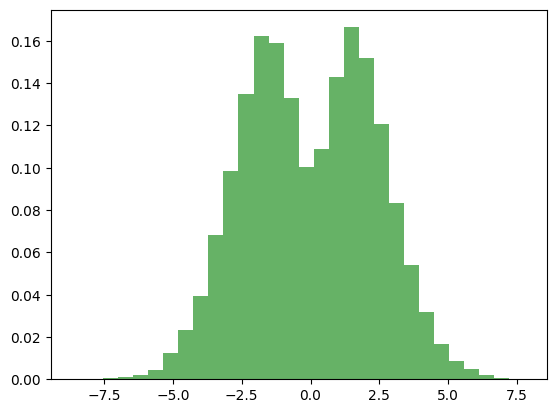

In [35]:
from scipy.stats import rv_continuous
class gaussian_gen(rv_continuous):
    "Gaussian distribution"
    def _pdf(self, x):
        return (5/3)*np.exp(-x**2 / (2*4))*(1 - (2/3)*np.exp(-x**2/(2*1))) / (5.864320374815367)
gaussian = gaussian_gen(name='toy_data')

# Sample some numbers from the distribution
samples = gaussian.rvs(size=20000, random_state=42)
# Plot the histogram of the samples
plt.hist(samples, bins=30, density=True, alpha=0.6, color='g')
# Plot the PDF

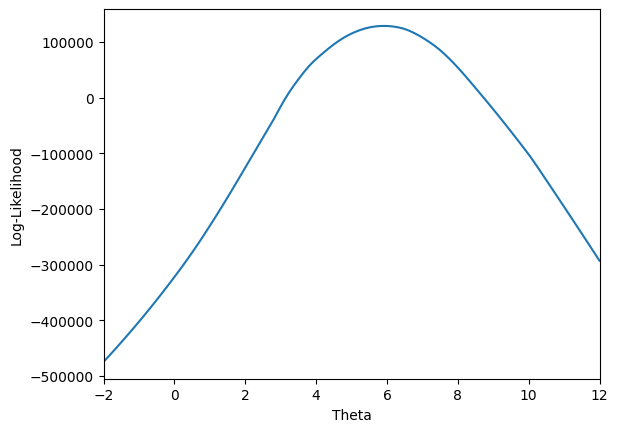

MLE estimate for theta: 5.919191919191919


In [38]:
def ratio(x_obs, theta, model):
    X = torch.cat([x_obs, theta], dim=1)
    logits = model(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood(theta, X_obs, model_pp, model_pn, c0, c1):
    # X_obs: shape [N, x_dim]
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    r_pp = ratio(X_obs, thetas, model_pp)
    r_pn = ratio(X_obs, thetas, model_pn)
    r_vals = r_pp * c1/c0 + r_pn * (1-c1)/c0
    return torch.sum(torch.log(r_vals))


fake_data = np.array(samples) + 5.9

new_X_p = np.random.normal(loc = 7.4, scale = 2.0, size = (n_signal_events_p, n_gaussian_dim))
new_X_n = np.random.normal(loc = 7.4, scale = 1.0, size = (n_signal_events_n, n_gaussian_dim))
new_data = np.random.choice(fake_data, size=(n_signal_events, n_gaussian_dim)).astype(np.float32) # np.concatenate((new_X_p, new_X_n), axis = 0)
new_data = np.concatenate((new_data, np.full((n_signal_events, 1), fill_value=3.4), np.full((n_signal_events, 1), fill_value=2)), axis=1).astype(np.float32)

new_data   = scaler.transform(new_data)
new_data = new_data[:,:-2]
new_X = torch.tensor(new_data, requires_grad=False)

# Generate new data for parameter estimation
log_likelihoods = []
x = np.linspace(-2,12,100)
for ix in x: # Scan over different theta values
    theta_tensor = torch.tensor([min_max_scaler(min_theta, max_theta, ix)], requires_grad=False, dtype=torch.float32)
    llh = log_likelihood(theta_tensor, new_X, model_pp, model_pn, C_zero, C_one) # Evaluate using the ML model!
    log_likelihoods.append(llh.item())

plt.plot(x, log_likelihoods)
plt.xlabel("Theta")
plt.ylabel("Log-Likelihood")
plt.xlim((min(x),max(x)))
plt.show()

# Get the MLE estimate for theta
np.argmax(log_likelihoods)
theta_mle = x[np.argmax(log_likelihoods)]
print("MLE estimate for theta:", theta_mle)

other_log_likelihoods = log_likelihoods